# County Education Office: Student Performance EDA
**Analyst:** Stanley Wanyoike Ngugi

**Purpose:** Identify which learners are most at risk of poor performance and which factors are associated with better results, to guide where a learner-support programme should be targeted. The analysis follows five EDA steps (Structure, Univariate, Bivariate, Multivariate, Hypotheses), then Findings, Recommendations and Limitations.

In [1]:
import os
if not os.path.exists("generate_data.py"):
    !git clone https://github.com/SWNgugi/plp-da-a4-student-eda-and-board-report.git
    %cd plp-da-a4-student-eda-and-board-report

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if not os.path.exists("student_performance.csv"):
    !python generate_data.py
os.makedirs("figures", exist_ok=True)

fatal: destination path 'plp-da-a4-student-eda-and-board-report' already exists and is not an empty directory.
/content/plp-da-a4-student-eda-and-board-report


## Structure
### Task 1: Grain, variables and data quality
I loaded the file and checked its shape, types, missing values, duplicates and value ranges before analysing anything.

In [2]:
students = pd.read_csv("student_performance.csv")
display(students.head())
print("Shape:", students.shape)
students.info()
print("\nMissing values per column:\n", students.isna().sum())
print("\nDuplicate rows:", students.duplicated().sum())
print("student_id unique:", students["student_id"].is_unique)
display(students.describe().loc[["min", "max"]].round(2))
print("Scores capped at 100:", (students[["math", "english", "science"]] == 100).sum().to_dict())

,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0


Shape: (1200, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       1200 non-null   int64  
 1   county           1200 non-null   object 
 2   school_type      1200 non-null   object 
 3   gender           1200 non-null   object 
 4   attendance_rate  1200 non-null   float64
 5   study_hours      1200 non-null   float64
 6   math             1200 non-null   float64
 7   english          1200 non-null   float64
 8   science          1200 non-null   float64
dtypes: float64(5), int64(1), object(3)
memory usage: 84.5+ KB

Missing values per column:
 student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math               0
english            0
science            0
dtype: int64

Duplicate rows: 0
student_id unique: True


,student_id,attendance_rate,study_hours,math,english,science
min,1.0,0.33,0.2,37.0,47.0,35.0
max,1200.0,1.00,23.3,100.0,100.0,100.0


Scores capped at 100: {'math': 11, 'english': 21, 'science': 16}


**Grain:** one row per student (1,200 students, each with a unique `student_id`).

| Variable | Type |
|---|---|
| student_id | identifier (integer), not analysed |
| county (6), school_type (2), gender (2) | categorical (nominal) |
| attendance_rate | numerical, continuous, a proportion from 0.33 to 1.00 |
| study_hours | numerical, continuous, hours (the recording period is not stated) |
| math, english, science | numerical, test scores out of 100 |

**Data quality:** no missing values, no duplicate rows or IDs, and all values are in valid ranges. One note: a few scores sit exactly at the ceiling of 100 (11 maths, 21 English, 16 science), which can slightly flatten differences among top performers.

## Univariate
### Task 2: Numerical and categorical summaries
Centre (mean, median), spread (standard deviation, IQR) and shape (skewness) for each numerical variable, counts and shares for each categorical one, and the IQR rule (1.5 × IQR beyond Q1 and Q3) to find outliers in study hours.

In [3]:
num_cols = ["attendance_rate", "study_hours", "math", "english", "science"]
summary = pd.DataFrame({
    "mean": students[num_cols].mean(),
    "median": students[num_cols].median(),
    "std": students[num_cols].std(),
    "IQR": students[num_cols].quantile(0.75) - students[num_cols].quantile(0.25),
    "skew": students[num_cols].skew(),
}).round(2)
display(summary)

for col in ["county", "school_type", "gender"]:
    display(pd.DataFrame({"count": students[col].value_counts(),
                          "share": students[col].value_counts(normalize=True).round(3)}))

q1, q3 = students["study_hours"].quantile([0.25, 0.75])
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = students[(students["study_hours"] < low_fence) | (students["study_hours"] > high_fence)]
print(f"IQR fences: {low_fence:.1f} to {high_fence:.1f}")
print(f"study_hours outliers: {len(outliers)} (max {outliers['study_hours'].max()})")

,mean,median,std,IQR,skew
attendance_rate,0.80,0.82,0.12,0.17,-0.86
study_hours,5.08,4.50,3.03,3.80,1.17
math,71.89,72.00,10.86,14.00,0.10
english,74.52,74.00,10.49,14.00,0.16
science,69.61,69.00,12.02,17.00,0.11


,count,share
county,,
Mombasa,212,0.177
Kisumu,208,0.173
Nyeri,203,0.169
Nakuru,202,0.168
Turkana,191,0.159
Nairobi,184,0.153


,count,share
school_type,,
Public,866,0.722
Private,334,0.278


,count,share
gender,,
F,612,0.51
M,588,0.49


IQR fences: -2.8 to 12.4
study_hours outliers: 29 (max 23.3)


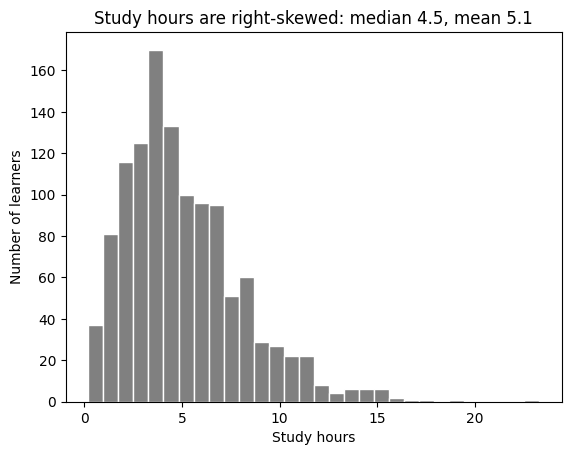

In [4]:
med, mean = students["study_hours"].median(), students["study_hours"].mean()
ax = students["study_hours"].plot(kind="hist", bins=30, color="grey", edgecolor="white",
                                  title=f"Study hours are right-skewed: median {med:.1f}, mean {mean:.1f}")
ax.set_xlabel("Study hours")
ax.set_ylabel("Number of learners")
ax.figure.savefig("figures/hist_study_hours.png", dpi=150, bbox_inches="tight")
plt.show()

**Centre, spread and shape.** Study hours are strongly right-skewed (skew 1.17; mean 5.08 is above the median 4.50), so a few learners study far more than the rest. Attendance is left-skewed (skew -0.86): most learners attend 73% to 90% of the time, with a tail of low attenders. The three subject scores are roughly symmetric (skew 0.10 to 0.16), with means of 71.9 (maths), 74.5 (English) and 69.6 (science). The sample is 72.2% public and 27.8% private, 51.0% female and 49.0% male, and county shares range from 15.3% (Nairobi) to 17.7% (Mombasa).

**Outliers.** 29 learners study more than 12.4 hours (maximum 23.3); there are no low outliers. These are plausible for very motivated learners, so I keep them, but they matter for any straight-line fit (see Hypotheses). Chart: `figures/hist_study_hours.png`.

### Task 3: average_score and performance_band
`average_score` is the mean of the three subjects. `pd.cut` with `right=False` gives At Risk below 60, Meeting from 60 up to (not including) 75, and Exceeding at 75 or above. Using the default `right=True` would wrongly push a score of exactly 60 or 75 into the lower band.

In [5]:
students["average_score"] = students[["math", "english", "science"]].mean(axis=1)
students["performance_band"] = pd.cut(students["average_score"],
                                      bins=[-np.inf, 60, 75, np.inf],
                                      labels=["At Risk", "Meeting", "Exceeding"],
                                      right=False)
band_counts = students["performance_band"].value_counts().reindex(["At Risk", "Meeting", "Exceeding"])
display(pd.DataFrame({"count": band_counts, "share": (band_counts / len(students)).round(3)}))
display(students["average_score"].describe().round(2))

,count,share
performance_band,,
At Risk,99,0.082
Meeting,672,0.560
Exceeding,429,0.358


,average_score
count,1200.00
mean,72.01
std,9.11
min,48.33
25%,65.67
50%,71.67
75%,77.67
max,100.00


## Bivariate
### Task 4: Correlations
Pearson and Spearman correlations between all numerical variables (excluding the ID), plus a 1/0 private-school flag for the school-type link.

,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.00,-0.03,0.30,0.33,0.26,0.36
study_hours,-0.03,1.00,0.56,0.62,0.55,0.70
math,0.30,0.56,1.00,0.56,0.46,0.81
english,0.33,0.62,0.56,1.00,0.50,0.83
science,0.26,0.55,0.46,0.50,1.00,0.82
average_score,0.36,0.70,0.81,0.83,0.82,1.00


Spearman with average_score:
 attendance_rate    0.34
study_hours        0.66
math               0.79
english            0.81
science            0.80
average_score      1.00
Name: average_score, dtype: float64
Correlation of private school (1/0) with average_score: 0.27


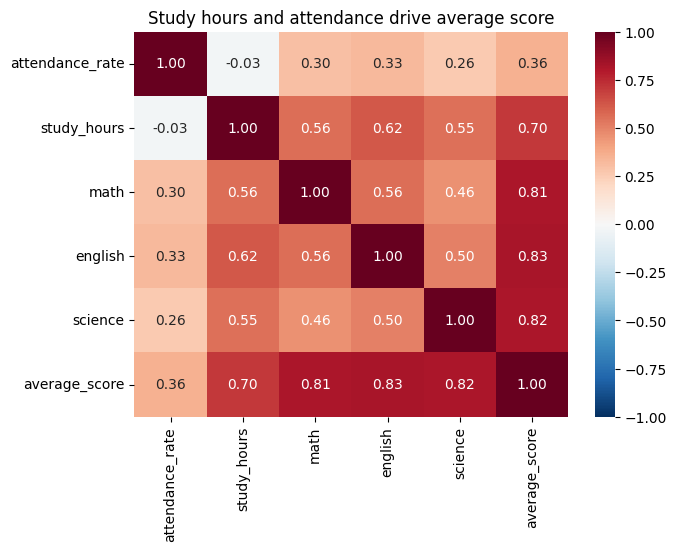

In [6]:
corr_cols = ["attendance_rate", "study_hours", "math", "english", "science", "average_score"]
pearson = students[corr_cols].corr()
display(pearson.round(2))
spearman = students[corr_cols].corr(method="spearman")
print("Spearman with average_score:\n", spearman["average_score"].round(2))

students["is_private"] = (students["school_type"] == "Private").astype(int)
print("Correlation of private school (1/0) with average_score:",
      round(students["is_private"].corr(students["average_score"]), 2))

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Study hours and attendance drive average score")
fig.savefig("figures/corr_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Three strongest relationships with average_score.** English (r = 0.83), science (0.82) and maths (0.81) are the strongest, but average_score is built from them, so these high values are mechanical and say nothing about causes. The strongest *external* relationships are:
1. **Study hours (r = 0.70):** strong and positive; learners who study more score higher.
2. **Attendance rate (r = 0.36):** moderate and positive.
3. **Private school (r = 0.27):** weak to moderate; private-school learners score higher.

Study hours and attendance are almost unrelated to each other (r = -0.03), so each adds separate information. Spearman results (0.66 and 0.34) agree with Pearson, so the pattern is not driven by the skew or outliers in study hours. Chart: `figures/corr_heatmap.png`.

### Task 5: Group comparisons
Average scores by gender, school type and county, then the share of learners in the At Risk band by county.

In [7]:
for col in ["gender", "school_type", "county"]:
    display(students.groupby(col)["average_score"].agg(mean="mean", n="count").round(2))

students["at_risk"] = students["performance_band"] == "At Risk"
risk_by_county = (students.groupby("county")["at_risk"].mean() * 100).round(1).sort_values(ascending=False)
risk_n = students.groupby("county")["at_risk"].sum()
display(pd.DataFrame({"at_risk_share_%": risk_by_county, "at_risk_learners": risk_n[risk_by_county.index]}))
print("Highest At Risk share:", risk_by_county.idxmax(), f"({risk_by_county.max()}%)")
print((students.groupby("school_type")["at_risk"].mean() * 100).round(1))

,mean,n
gender,,
F,72.10,612
M,71.91,588


,mean,n
school_type,,
Private,76.01,334
Public,70.46,866


,mean,n
county,,
Kisumu,73.07,208
Mombasa,72.17,212
Nairobi,71.96,184
Nakuru,71.84,202
Nyeri,71.94,203
Turkana,70.97,191


,at_risk_share_%,at_risk_learners
county,,
Nairobi,9.2,17
Mombasa,9.0,19
Nyeri,8.9,18
Kisumu,8.2,17
Turkana,7.9,15
Nakuru,6.4,13


Highest At Risk share: Nairobi (9.2%)
school_type
Private     1.5
Public     10.9
Name: at_risk, dtype: float64


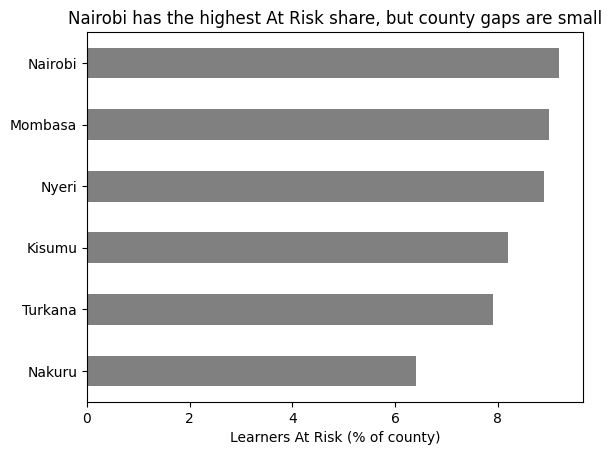

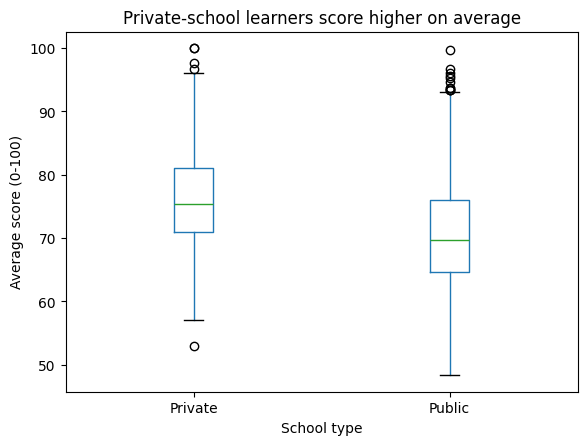

In [8]:
ax = risk_by_county.sort_values().plot(kind="barh", color="grey",
        title=f"{risk_by_county.idxmax()} has the highest At Risk share, but county gaps are small")
ax.set_xlabel("Learners At Risk (% of county)")
ax.set_ylabel("")
ax.figure.savefig("figures/bar_at_risk_by_county.png", dpi=150, bbox_inches="tight")
plt.show()

ax = students.boxplot(column="average_score", by="school_type", grid=False)
plt.suptitle("")
ax.set_title("Private-school learners score higher on average")
ax.set_xlabel("School type")
ax.set_ylabel("Average score (0-100)")
ax.figure.savefig("figures/box_score_by_school_type.png", dpi=150, bbox_inches="tight")
plt.show()

**Gender:** female and male learners score almost identically (72.10 vs 71.91, a gap of 0.19 points), so gender is not a useful targeting factor.

**School type:** private-school learners average 76.01 against 70.46 in public schools (a 5.55-point gap), and only 1.5% of private learners are At Risk versus 10.9% of public learners.

**County:** mean scores range only from 70.97 (Turkana) to 73.07 (Kisumu). **Nairobi has the highest share of At Risk learners (9.2%, 17 of 184)**, but the spread across counties is just 6.4% to 9.2% (13 to 19 learners per county), small enough that chance variation could explain it. Mombasa actually has the most At Risk learners (19). Charts: `figures/bar_at_risk_by_county.png` and `figures/box_score_by_school_type.png`.

## Multivariate
### Task 6: Does the school-type gap persist?
Attendance is grouped into bands (below 70%, 70% to under 85%, 85% and above) and study hours into quartiles (`pd.qcut`). Pivot tables then show the average score by school type within each group, with the Private minus Public gap and the group sizes.

In [9]:
students["attendance_band"] = pd.cut(students["attendance_rate"], bins=[0, 0.70, 0.85, 1.01],
                                     labels=["Below 70%", "70-85%", "85%+"], right=False)
students["study_quartile"] = pd.qcut(students["study_hours"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
display(students["attendance_band"].value_counts().reindex(["Below 70%", "70-85%", "85%+"]))
display(students.groupby("study_quartile", observed=True)["study_hours"].agg(["min", "max"]))

def gap_table(row_col):
    """Mean average_score by row_col and school type, with the Private-Public gap, plus group sizes."""
    means = students.pivot_table(index=row_col, columns="school_type", values="average_score",
                                 aggfunc="mean", observed=True)
    means["gap (Private - Public)"] = means["Private"] - means["Public"]
    counts = students.pivot_table(index=row_col, columns="school_type", values="average_score",
                                  aggfunc="size", observed=True)
    return means.round(2), counts

for c in ["attendance_band", "study_quartile"]:
    means_tbl, counts_tbl = gap_table(c)
    display(means_tbl)
    display(counts_tbl)

display(students.groupby("attendance_band", observed=True)["average_score"].mean().round(2))
display(students.groupby("study_quartile", observed=True)["average_score"].mean().round(2))
display((students.groupby("attendance_band", observed=True)["at_risk"].mean() * 100).round(1))
display((students.groupby("study_quartile", observed=True)["at_risk"].mean() * 100).round(1))

,count
attendance_band,
Below 70%,207
70-85%,495
85%+,498


,min,max
study_quartile,,
Q1,0.2,2.9
Q2,3.0,4.5
Q3,4.6,6.7
Q4,6.8,23.3


school_type,Private,Public,gap (Private - Public)
attendance_band,,,
Below 70%,71.05,64.85,6.20
70-85%,75.60,69.25,6.35
85%+,78.65,73.93,4.72


school_type,Private,Public
attendance_band,,
Below 70%,61,146
70-85%,137,358
85%+,136,362


school_type,Private,Public,gap (Private - Public)
study_quartile,,,
Q1,69.51,63.82,5.69
Q2,74.92,67.12,7.80
Q3,76.18,71.18,5.00
Q4,83.65,80.06,3.59


school_type,Private,Public
study_quartile,,
Q1,84,227
Q2,86,216
Q3,82,206
Q4,82,217


,average_score
attendance_band,
Below 70%,66.68
70-85%,71.00
85%+,75.22


,average_score
study_quartile,
Q1,65.36
Q2,69.34
Q3,72.60
Q4,81.04


,at_risk
attendance_band,
Below 70%,24.2
70-85%,7.5
85%+,2.4


,at_risk
study_quartile,
Q1,21.2
Q2,7.9
Q3,2.8
Q4,0.3


In [10]:
flag = (students["attendance_band"] == "Below 70%") | (students["study_quartile"] == "Q1")
at_risk_total = students["at_risk"].sum()
print("Flagged learners:", flag.sum(), f"({flag.mean():.1%} of all)")
print("At Risk learners inside the flag:", (flag & students["at_risk"]).sum(),
      f"of {at_risk_total} ({(flag & students['at_risk']).sum() / at_risk_total:.1%})")
print(f"At Risk rate inside flag: {students.loc[flag, 'at_risk'].mean():.1%} | outside: {students.loc[~flag, 'at_risk'].mean():.1%}")
public_flag = flag & (students["school_type"] == "Public")
print("Public-school flagged learners:", public_flag.sum(),
      f"capturing {(public_flag & students['at_risk']).sum() / at_risk_total:.1%} of At Risk (At Risk rate {students.loc[public_flag, 'at_risk'].mean():.1%})")
print("At Risk learners in public schools:", (students["at_risk"] & (students["school_type"] == "Public")).sum(), "of", at_risk_total)

Flagged learners: 468 (39.0% of all)
At Risk learners inside the flag: 86 of 99 (86.9%)
At Risk rate inside flag: 18.4% | outside: 1.8%
Public-school flagged learners: 337 capturing 81.8% of At Risk (At Risk rate 24.0%)
At Risk learners in public schools: 94 of 99


**Answer: yes, the school-type gap persists at every attendance level and every study level.** Private learners score higher than public learners in all seven groups: by 6.20, 6.35 and 4.72 points across the three attendance bands, and by 5.69, 7.80, 5.00 and 3.59 points across the four study-hour quartiles. The gap is narrower for the most-attending (4.72) and most-studying (3.59) learners, possibly because scores near the ceiling of 100 compress differences. Group sizes are adequate (smallest cell: 61 private learners with attendance below 70%).

Both attendance and study time also show clear, graded effects: average scores rise from 66.68 (below 70% attendance) to 75.22 (85%+), and from 65.36 (Q1) to 81.04 (Q4) across study quartiles. The At Risk share falls from 24.2% to 2.4% across attendance bands and from 21.2% to 0.3% across study quartiles.

## Hypotheses
### Task 7: Trend line of average_score against study_hours
The dataset has no dates, so I fit a straight line with `np.polyfit` (degree 1). R² is the squared correlation, the share of variation in average_score explained by study hours.

average_score = 61.26 + 2.12 x study_hours
Slope: 2.12 points per extra study hour | R-squared: 0.50


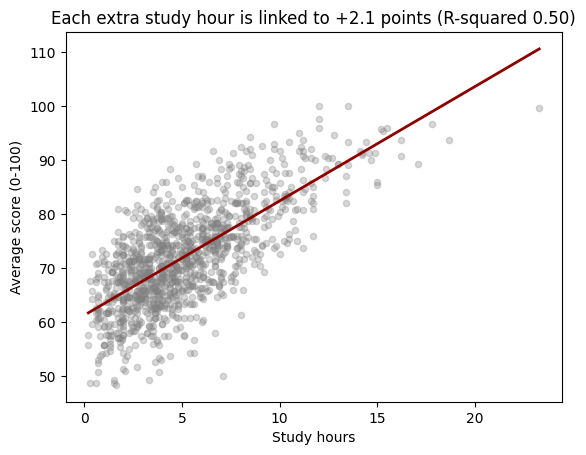

In [11]:
slope, intercept = np.polyfit(students["study_hours"], students["average_score"], 1)
r = students["study_hours"].corr(students["average_score"])
r_squared = r ** 2
print(f"average_score = {intercept:.2f} + {slope:.2f} x study_hours")
print(f"Slope: {slope:.2f} points per extra study hour | R-squared: {r_squared:.2f}")

ax = students.plot(kind="scatter", x="study_hours", y="average_score", alpha=0.3, color="grey",
                   title=f"Each extra study hour is linked to +{slope:.1f} points (R-squared {r_squared:.2f})")
xs = np.linspace(students["study_hours"].min(), students["study_hours"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="#8E0000", linewidth=2)
ax.set_xlabel("Study hours")
ax.set_ylabel("Average score (0-100)")
ax.figure.savefig("figures/scatter_trend_study_hours.png", dpi=150, bbox_inches="tight")
plt.show()

**What the slope means:** on average, learners who study one more hour have an average score 2.12 points higher, and study hours alone explain about half of the variation in scores (R² = 0.50).

**One limitation:** this is an association from a single snapshot, not proof that adding study hours would raise an individual learner's score, and the straight line is least reliable above about 12 hours, where only 29 learners are observed. Chart: `figures/scatter_trend_study_hours.png`.

### Testing the hypotheses
- **H1: study hours are positively associated with average score.**
- **H2: the private-school advantage is not explained away by attendance or study time.**
- **H3: county explains meaningful differences in performance.**

In [12]:
private = students.loc[students["school_type"] == "Private", "average_score"]
public = students.loc[students["school_type"] == "Public", "average_score"]
gap = private.mean() - public.mean()
se = np.sqrt(private.var() / len(private) + public.var() / len(public))
print(f"School-type gap: {gap:.2f} points, 95% CI {gap - 1.96*se:.2f} to {gap + 1.96*se:.2f}")
print("Figures saved:", sorted(os.listdir("figures")))

School-type gap: 5.55 points, 95% CI 4.49 to 6.60
Figures saved: ['bar_at_risk_by_county.png', 'box_score_by_school_type.png', 'corr_heatmap.png', 'hist_study_hours.png', 'scatter_trend_study_hours.png']


- **H1: supported.** r = 0.70, slope 2.12 points per hour, and mean scores climb steadily from 65.36 (Q1) to 81.04 (Q4).
- **H2: supported.** The overall gap is 5.55 points (95% CI 4.49 to 6.60) and the gap stays positive in all seven attendance and study groups (3.59 to 7.80 points).
- **H3: not supported.** County means span only 2.1 points and At Risk shares only 6.4% to 9.2% (13 to 19 learners), so county is a weak basis for targeting.

## Findings
1. **Study time is the strongest factor linked to performance.** Study hours correlate r = 0.70 with average score; each extra hour is associated with +2.12 points (R² = 0.50), and mean scores rise from 65.36 for the lowest study quartile to 81.04 for the highest (`figures/scatter_trend_study_hours.png`).
2. **Attendance matters too.** Learners attending below 70% average 66.68 versus 75.22 at 85% or more, and 24.2% of low attenders are At Risk versus 2.4% of high attenders (`figures/corr_heatmap.png`).
3. **Public-school learners are far more likely to be At Risk.** Private learners score 5.55 points higher (95% CI 4.49 to 6.60) and only 1.5% are At Risk against 10.9% in public schools; the gap persists in every attendance and study group (`figures/box_score_by_school_type.png`).
4. **Gender and county are weak signals.** Female and male averages differ by 0.19 points, county averages by at most 2.1 points, and At Risk shares range only from 6.4% to 9.2%. Nairobi is highest (9.2%, 17 learners) but Mombasa has the most At Risk learners (19) (`figures/bar_at_risk_by_county.png`).
5. **Risk is concentrated and easy to screen for.** 99 learners (8.2%) are At Risk. Flagging learners with attendance below 70% or in the lowest study quartile (468 learners, 39.0% of all) captures 86 of the 99 (86.9%), with an At Risk rate of 18.4% inside the flag versus 1.8% outside.

## Recommendations
1. **Target the programme by attendance and study habits, not by county or gender.** Screen for learners with attendance below 70% or fewer than 3 study hours (the lowest quartile, up to 2.9 hours). This reaches 86.9% of At Risk learners with 39.0% of the learner population, and 50 learners fall in both groups at once, where 60% are At Risk.
2. **Prioritise public schools within that group.** 94 of the 99 At Risk learners are in public schools, and the 337 flagged public-school learners contain 81.8% of all At Risk learners (an At Risk rate of 24.0%). Pilot attendance and structured study support there first, with a comparison group so the programme's effect can be measured before scaling.

## Limitations
These results are associations from a single snapshot of 1,200 learners, not proof of cause and effect: learners who study more may also differ in motivation, home support or prior attainment, none of which are recorded. The school-type gap may reflect which families choose private schools rather than what the schools do. Study hours have no stated unit or recording period, and the straight-line fit explains only half of the variation (R² = 0.50) and is unreliable above about 12 hours (29 outliers kept in the data). A few scores are capped at 100, which can understate differences among top performers. Some subgroups are small (for example, 61 private learners with attendance below 70%), and county differences are small enough to be explained by chance. The programme should therefore be piloted and evaluated, not assumed to work.

In [13]:
both = (students["attendance_band"] == "Below 70%") & (students["study_quartile"] == "Q1")
print("In both groups:", both.sum(), f"| At Risk rate: {students.loc[both, 'at_risk'].mean():.1%}")

In both groups: 50 | At Risk rate: 60.0%
